# A telescope zoo: Newtonian, Cassegrain, Ritchey–Chrétien and Schmidt

Every large telescope since the 19th century gathers its light with a
concave mirror. A mirror has no chromatic aberration, it can be supported
from behind, and a single conic surface images a star on the axis
perfectly: the paraboloid. Off the axis the paraboloid fails, and most of
the history of telescope design is about what to do with the field: the
Cassegrain folds the beam with a second mirror, the Ritchey–Chrétien
reshapes both mirrors to remove coma, and the Schmidt camera gives up the
paraboloid altogether for a sphere with a thin corrector plate at its
centre of curvature.

This notebook traces the four designs with `pyoptics.raytrace` (the
builders are in `pyoptics.telescopes`) and checks every effect against the
closed form third order theory of conic mirrors (Schwarzschild 1905,
Schroeder's *Astronomical Optics*):

1. one mirror: the spherical aberration of a sphere and of other conics,
   $W_{040} = -(1+K)\,y^4/(32 f^3)$, and why the paraboloid is perfect on
   the axis,
2. the Newtonian: coma grows linearly with the field angle, angular
   tangential coma $3\theta/(16F^2)$, and the diffraction limited field,
3. classical Cassegrain against Ritchey–Chrétien: the same first order
   layout, the Schwarzschild conics, the coma of the classical Cassegrain
   is that of a paraboloid of the same focal ratio, the RC has none,
4. what is left: astigmatism and field curvature, the medial image
   surface against best focus traced through the field,
5. the Schmidt camera: no coma and no astigmatism at all, a curved focal
   surface concentric with the mirror, and the chromatic blur of the
   corrector plate, $\delta n/(128 (n-1) F^3)$.

Everything is geometrical optics (spot diagrams and wavefronts from real
rays); the Airy disk is drawn for scale. Notebook 72 covers what the
atmosphere does to these images, notebook 96 coronagraphs and notebook 74
stellar interferometry. Lengths are in mm.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import raytrace as rt
from pyoptics import sketch
from pyoptics import telescopes as tl

t_start = time.time()
lam = 550e-6                         # mm
arcsec = np.pi/180/3600


def show_spot(ax, s, scale, airy=None, color="C0", title=None):
    # spot diagram in micrometres, centred on the centroid
    ax.plot((s.x - s.centroid[0])*1e3, (s.y - s.centroid[1])*1e3, ".", ms=1.5, color=color)
    if airy is not None:
        t = np.linspace(0, 2*np.pi, 200)
        ax.plot(airy*1e3*np.cos(t), airy*1e3*np.sin(t), color="0.4", lw=0.8)
    ax.set_xlim(-scale, scale)
    ax.set_ylim(-scale, scale)
    ax.set_aspect("equal")
    ax.tick_params(labelsize=7)
    if title:
        ax.set_title(title, fontsize=9)

## The setups

Three layouts, schematically (the proportions are chosen for clarity). In
the **Newtonian** a flat diagonal sends the focus of a paraboloid to the
side of the tube; it only folds the beam and is left out of the traces.
The **Cassegrain** puts a convex mirror in front of the focus of the
primary; it multiplies the focal length by $m = f/f_1$ and brings the
focus through a hole in the primary to a distance $b$ behind it. The
classical Cassegrain pairs a paraboloid with a hyperboloid, the
Ritchey–Chrétien two hyperboloids. The **Schmidt camera** has its stop and
a thin aspheric plate at the centre of curvature of a spherical mirror;
every chief ray passes through that centre, so every field angle sees the
same mirror, and the image lies on a sphere of radius $f$.

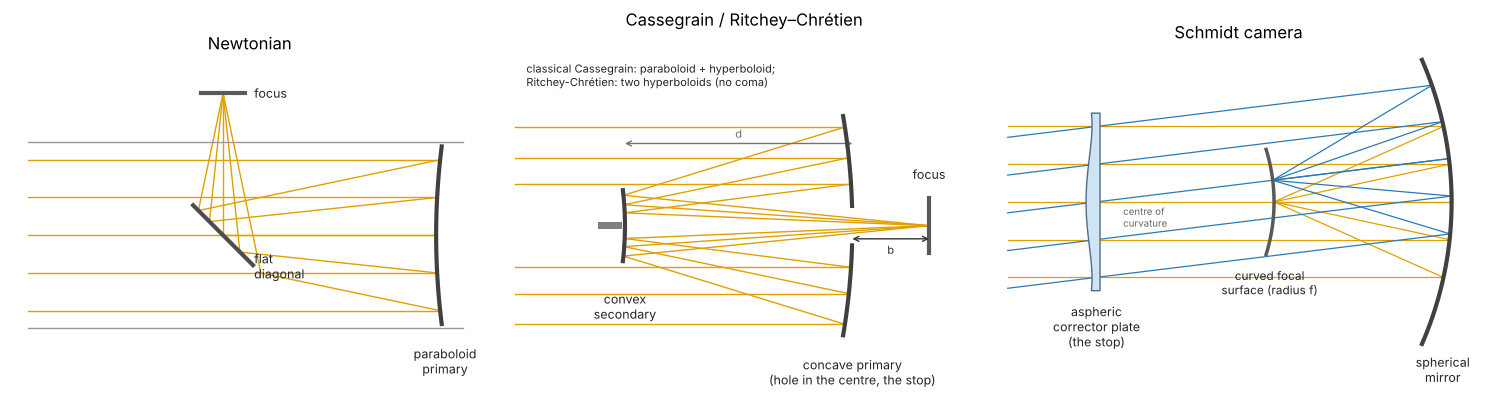

In [2]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
sketch.telescope_layout(axs[0], "newtonian", title="Newtonian")
sketch.telescope_layout(axs[1], "cassegrain", title="Cassegrain / Ritchey–Chrétien")
sketch.telescope_layout(axs[2], "schmidt", title="Schmidt camera")
plt.tight_layout()
plt.show()

## 1. One mirror: spherical aberration of conics

A conic mirror of vertex radius $R = 2f$ and conic constant $K$ (0 sphere,
$-1$ paraboloid, $<-1$ hyperboloid, between $-1$ and 0 a prolate
ellipsoid), with the stop at the mirror, has the third order wavefront
aberration (in the sign convention of `raytrace`, negative for an
undercorrected mirror) ::

$$W_{040} = -\frac{(1+K)\,y^4}{32 f^3}$$

at the rim of the aperture $y = D/2$. The paraboloid ($K=-1$) is free of
spherical aberration to all orders: it is the surface that sends every
ray parallel to the axis to the focus. Below, a 200 mm f/4 mirror with
several conics: the Seidel sum, the traced Zernike coefficients (for pure
spherical aberration the Fringe $Z_9 = W_{040}/6$) and the formula.

In [3]:
D_n, F_n = 200.0, 4.0
f_n = D_n*F_n
print("%7s %14s %14s %14s %12s" % ("K", "formula/waves", "Seidel/waves", "6 Z9/waves",
                                    "rms/waves"))
for K in (0.0, -0.5, -1.0, -1.5):
    M = tl.newtonian(D_n, F_n, conic=K, wavelength=lam)
    W040 = tl.mirror_aberrations(D_n, f_n, K, 0.0).W040/lam
    z = M.zernike(0.0, 16)
    print("%7.2f %14.3f %14.3f %14.3f %12.4f" % (K, W040, M.seidel(0.0).W040, 6*z[8],
                                                  M.rms_opd(0.0)))

      K  formula/waves   Seidel/waves     6 Z9/waves    rms/waves
   0.00        -11.097        -11.097        -11.065       3.2574


  -0.50         -5.549         -5.549         -5.524       1.6272
  -1.00         -0.000          0.000          0.000       0.0000
  -1.50          5.549          5.549          5.508       1.6243


The sphere at f/4 has 11 waves of spherical aberration, the paraboloid
none; the traced coefficient differs from the third order one only by the
higher orders (a few per mille at f/4). How much spherical aberration is
tolerable? Balanced against defocus, the rms of $W_{040}\rho^4$ is
$W_{040}/\sqrt{180}$, and the Maréchal criterion (rms $\le \lambda/14$)
gives $W_{040} \le 0.96\lambda$. With $W_{040} = D/(512F^3)$ for a sphere, it
is good enough as long as

$$F \ge \left(\frac{D}{512\cdot 0.96\,\lambda}\right)^{1/3},$$

f/9 for a 200 mm mirror at 550 nm and f/6.6 for the classic 3 inch
amateur telescope. Below, the spot diagrams of the sphere and
of the paraboloid at f/4, with the Airy disk (radius $1.22\lambda F$).

sphere good enough for F >= 9.0 (D = 200 mm), 6.6 (D = 76 mm)


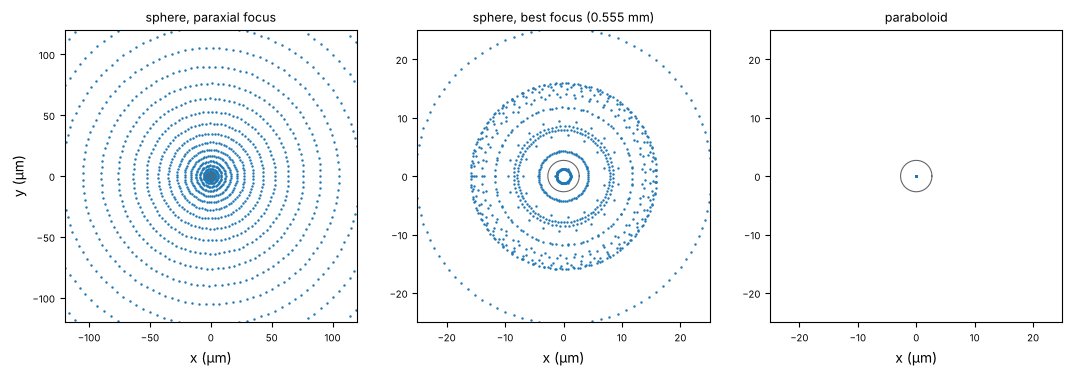

sphere: rms spot radius at best focus 53.7 µm, Airy radius 2.68 µm


In [4]:
print("sphere good enough for F >= %.1f (D = 200 mm), %.1f (D = 76 mm)"
      % ((200/(512*0.96*lam))**(1/3), (76/(512*0.96*lam))**(1/3)))

sph = tl.newtonian(D_n, F_n, conic=0.0, wavelength=lam)
par = tl.newtonian(D_n, F_n, conic=-1.0, wavelength=lam)
dz_s, rms_s = tl.best_focus(sph, 0.0, search=0.5)
airy_n = 1.22*lam*F_n
fig, axs = plt.subplots(1, 3, figsize=(11, 3.6))
show_spot(axs[0], tl.spot(sph, 0.0, n_rings=24), 120, airy_n, title="sphere, paraxial focus")
show_spot(axs[1], tl.spot(sph.with_image_distance(sph.surfaces[-1].thickness + dz_s), 0.0,
                          n_rings=24), 25, airy_n,
          title="sphere, best focus (%.3f mm)" % dz_s)
show_spot(axs[2], tl.spot(par, 0.0, n_rings=24), 25, airy_n, title="paraboloid")
for ax in axs:
    ax.set_xlabel("x (µm)")
axs[0].set_ylabel("y (µm)")
plt.tight_layout()
plt.show()
print("sphere: rms spot radius at best focus %.1f µm, Airy radius %.2f µm" % (rms_s*1e3, airy_n*1e3))

## 2. The Newtonian: coma

Off the axis the paraboloid shows coma. With the stop at the mirror its
third order coefficient is $W_{131} = y^3\theta/(4f^2)$, independent of
the conic constant (the conic changes only the spherical aberration when
the stop is at the mirror). In the image, the rays through a zone of the
pupil form a circle displaced from the chief ray; the rim rays of the
tangential fan meet at the tip of the comet, a distance $f\cdot\mathrm{ACC}$
from the chief ray, with the *angular tangential coma*

$$\mathrm{ACC} = \frac{3W_{131}}{y} = \frac{3\theta}{16F^2}.$$

The length of the comet is three times the radius of the outer circle and
grows linearly with the field angle. Below: spot diagrams of the 200 mm
f/4 paraboloid at four field angles, and the tangential ray fan.

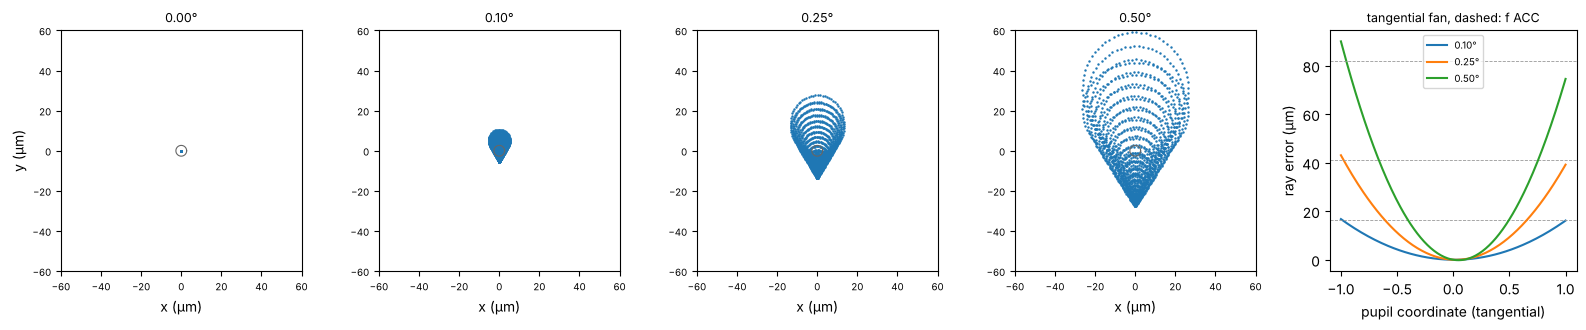

 field    traced tip/µm         f ACC/µm      ratio
 0.10°            16.45            16.36     1.0052
 0.25°            41.12            40.91     1.0053
 0.50°            82.25            81.81     1.0054
 1.00°           164.56           163.62     1.0057


In [5]:
fields_n = np.radians([0.0, 0.1, 0.25, 0.5])
fig, axs = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, th in zip(axs, fields_n):
    s = tl.spot(par, th, n_rings=24)
    show_spot(ax, s, 60, airy_n, title="%.2f°" % np.degrees(th))
    ax.set_xlabel("x (µm)")
axs[0].set_ylabel("y (µm)")
p = np.linspace(-1, 1, 201)
for th in fields_n[1:]:
    fan = par.ray_fan(th, 201)
    axs[4].plot(p, fan.ey*1e3, label="%.2f°" % np.degrees(th))
    acc = tl.mirror_aberrations(D_n, f_n, -1.0, th).ACC
    axs[4].axhline(f_n*acc*1e3, color="0.6", lw=0.6, ls="--")
axs[4].set_xlabel("pupil coordinate (tangential)")
axs[4].set_ylabel("ray error (µm)")
axs[4].legend(fontsize=7)
axs[4].set_title("tangential fan, dashed: f ACC", fontsize=9)
plt.tight_layout()
plt.show()

print("%6s %16s %16s %10s" % ("field", "traced tip/µm", "f ACC/µm", "ratio"))
for th in np.radians([0.1, 0.25, 0.5, 1.0]):
    fan = par.ray_fan(th, 201)
    tip = (fan.ey[0] + fan.ey[-1])/2          # symmetric part: coma (the rest is defocus)
    acc = tl.mirror_aberrations(D_n, f_n, -1.0, th).ACC
    print("%5.2f° %16.2f %16.2f %10.4f" % (np.degrees(th), tip*1e3, f_n*acc*1e3, tip/(f_n*acc)))

The traced comet tip agrees with $f\cdot 3\theta/(16F^2)$ to a few per
mille. In Zernike terms coma is $Z_8 = W_{131}/3$ (Fringe ordering), and
its rms over the pupil is $W_{131}/\sqrt{72}$. Setting that to the
Maréchal limit $\lambda/14$ gives the radius of the diffraction limited
field of a paraboloid:

$$\theta_\mathrm{DL} = \frac{32\sqrt{72}}{14}\,\frac{F^2\lambda}{D}.$$

It grows with $F^2$: a fast paraboloid has a tiny useful field. Below the
traced $Z_8$ against the field angle, and the coma limited field for
several focal ratios (and the field where the comet tip reaches 1
arcsecond, the size of a typical seeing disk).

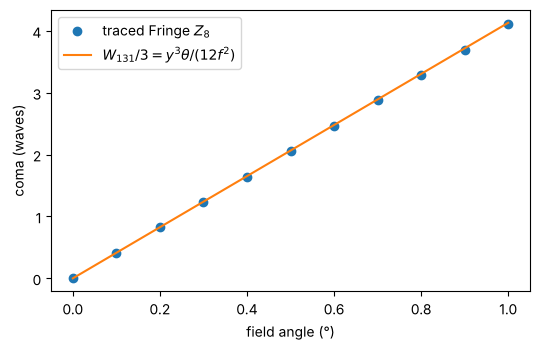

    F  diffraction limit (')  1 arcsec coma tip (')
    3                   1.65                   0.80
    4                   2.93                   1.42
    5                   4.58                   2.22
    6                   6.60                   3.20
    8                  11.73                   5.69
   10                  18.34                   8.89


In [6]:
th_n = np.radians(np.linspace(0, 1.0, 11))
z8 = np.array([par.zernike(t, 16)[7] for t in th_n])
W131 = np.array([tl.mirror_aberrations(D_n, f_n, -1.0, t).W131 for t in th_n])/lam
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(np.degrees(th_n), z8, "o", label="traced Fringe $Z_8$")
ax.plot(np.degrees(th_n), W131/3, "-", label=r"$W_{131}/3 = y^3\theta/(12 f^2)$")
ax.set_xlabel("field angle (°)")
ax.set_ylabel("coma (waves)")
ax.legend()
plt.tight_layout()
plt.show()

print("%5s %22s %22s" % ("F", "diffraction limit (')", "1 arcsec coma tip (')"))
for F in (3, 4, 5, 6, 8, 10):
    th_dl = 32*np.sqrt(72)/14*F**2*lam/D_n
    th_1 = arcsec*16*F**2/3
    print("%5d %22.2f %22.2f" % (F, np.degrees(th_dl)*60, np.degrees(th_1)*60))

At f/4 the 200 mm paraboloid is diffraction limited only within 2.9
arcminutes of the axis, a field a fifth of the Moon's diameter across. A Newtonian is
fine for visual observing of one object at a time; for wide fields it
needs a coma corrector.

## 3. Classical Cassegrain and Ritchey–Chrétien

A 1 m telescope with an f/3 primary ($f_1 = 3$ m), a system focal length of
8 m (f/8, secondary magnification $m = 8/3$) and the focus 300 mm behind
the primary ($\beta = b/f_1 = 0.1$). The first order layout is the same for
both designs; only the conic constants differ. Schwarzschild's conditions
for zero spherical aberration and zero coma give the Ritchey–Chrétien
conics ::

$$K_1 = -1 - \frac{2(1+\beta)}{m^2(m-\beta)}, \qquad
K_2 = -\left(\frac{m+1}{m-1}\right)^2 - \frac{2m(m+1)}{(m-\beta)(m-1)^3},$$

while the classical Cassegrain keeps a paraboloid primary and a
hyperboloid secondary with its foci in the two images,
$K_2 = -((m+1)/(m-1))^2$.

m = 2.6667, beta = 0.100, separation d = 2100.0 mm, secondary 900.0 mm in front of the primary focus
R1 = -6000.0 mm, R2 = -2880.0 mm, linear obscuration 0.300
classical  K1 =  -1.0000  K2 =  -4.8400  efl = 8000.00 mm, back focus 300.00 mm
RC         K1 =  -1.1205  K2 =  -6.4857  efl = 8000.00 mm, back focus 300.00 mm


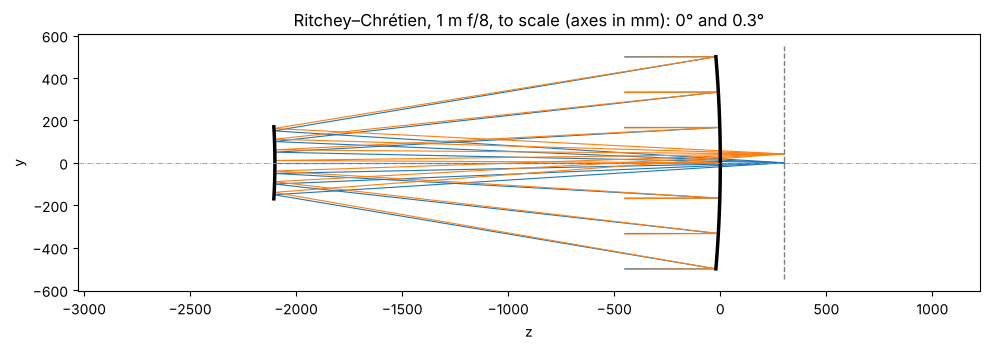

In [7]:
D, f1, f, b = 1000.0, 3000.0, 8000.0, 300.0
g = tl.two_mirror_geometry(f1, f, b)
cass = tl.two_mirror_telescope(D, f1, f, b, "classical", wavelength=lam)
rc = tl.two_mirror_telescope(D, f1, f, b, "rc", wavelength=lam)
print("m = %.4f, beta = %.3f, separation d = %.1f mm, secondary %.1f mm in front of the primary focus"
      % (g.m, g.beta, g.d, g.p))
print("R1 = %.1f mm, R2 = %.1f mm, linear obscuration %.3f" % (g.R1, g.R2, g.obscuration))
for name, S in (("classical", cass), ("RC", rc)):
    K = [s.conic for s in S.surfaces]
    print("%-10s K1 = %8.4f  K2 = %8.4f  efl = %.2f mm, back focus %.2f mm"
          % (name, K[0], K[1], S.paraxial().efl, S.paraxial().image_distance - g.d))

fig, ax = plt.subplots(figsize=(10, 3.6))
rc.draw(ax, fields=[0.0, np.radians(0.3)])
ax.set_title("Ritchey–Chrétien, 1 m f/8, to scale (axes in mm): 0° and 0.3°")
plt.tight_layout()
plt.show()

The Seidel sums show how the two mirrors share the work. In the classical
Cassegrain each mirror is free of spherical aberration on its own (the
paraboloid for the object at infinity, the hyperboloid between its two
foci), and the coma is that of the paraboloid. The RC makes the primary
more hyperbolic, which adds spherical aberration that the secondary
removes again, and changes the coma of the two mirrors so that they cancel.
Per surface wavefront coefficients at 0.2° (in waves):

In [8]:
th = np.radians(0.2)
for name, S in (("classical", cass), ("RC", rc)):
    sd = S.seidel(th)
    print(name)
    print("  %-10s %10s %10s %10s %10s" % ("", "W040", "W131", "W222", "W220"))
    for lab, row in zip(("primary", "secondary", "total"), list(sd.W[:, :4]) + [sd.W.sum(0)[:4]]):
        print("  %-10s %10.3f %10.3f %10.3f %10.3f" % (lab, *row))

classical
                   W040       W131       W222       W220
  primary         0.000     22.037     -0.923      0.000
  secondary      -0.000    -18.938      0.072     -0.925
  total          -0.000      3.099     -0.851     -0.925
RC
                   W040       W131       W222       W220
  primary        15.853     22.037     -0.923      0.000
  secondary     -15.853    -22.037     -0.079     -1.001
  total          -0.000     -0.000     -1.002     -1.001


Now the coma. The angular tangential coma of the classical Cassegrain is
that of a paraboloid of the system focal ratio, $3\theta/(16F^2)$ with
$F = 8$: the secondary magnifies the image of the f/3 primary, and its
coma, by $m$, which is exactly what a slower paraboloid would have. From
the traced Fringe $Z_8$ the angular coma is $9 Z_8 \lambda/y$:

In [9]:
print("%6s %18s %18s %18s %14s" % ("field", "classical traced", "classical formula",
                                    "paraboloid f/8", "RC traced"))
for deg in (0.1, 0.2, 0.3):
    th = np.radians(deg)
    a = tl.two_mirror_aberrations(D, f1, f, b, th, "classical")
    acc_c = 9*cass.zernike(th, 16)[7]*lam/(D/2)
    acc_r = 9*rc.zernike(th, 16)[7]*lam/(D/2)
    acc_p = tl.mirror_aberrations(D, f, -1.0, th).ACC
    print("%5.1f° %16.3f\" %16.3f\" %16.3f\" %12.4f\""
          % (deg, acc_c/arcsec, a.ACC/arcsec, acc_p/arcsec, acc_r/arcsec))

 field   classical traced  classical formula     paraboloid f/8      RC traced


  0.1°            1.053"            1.055"            1.055"       0.0071"


  0.2°            2.106"            2.109"            2.109"       0.0135"


  0.3°            3.158"            3.164"            3.164"       0.0187"


Spot diagrams through the field, each at its best focus (the image
surface is curved, see the next section), with the 30 % central
obscuration of the secondary and the Airy disk of the 1 m f/8 telescope.
The classical Cassegrain has the comet of a paraboloid; the RC is left
with a small symmetric blur, astigmatism, that grows with the square of
the field angle.

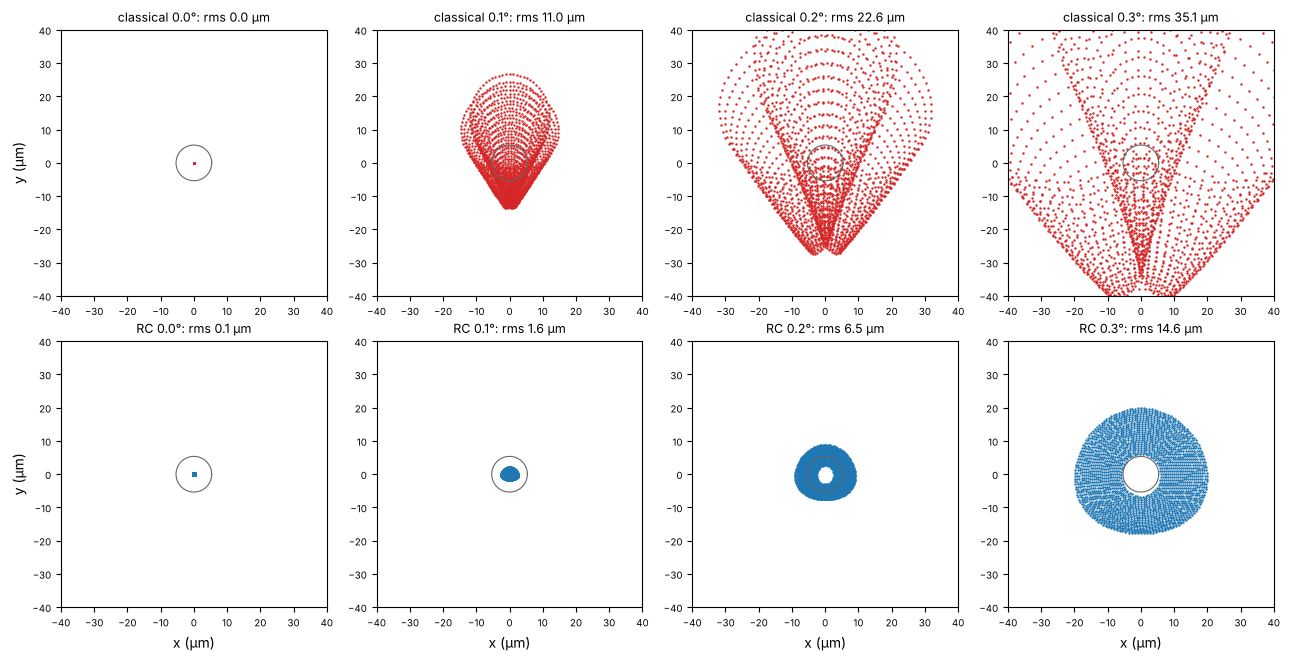

Airy radius 5.4 µm = 0.138 arcsec; 1 arcsec = 38.8 µm at f = 8 m


In [10]:
fields = np.radians([0.0, 0.1, 0.2, 0.3])
airy = 1.22*lam*f/D
eps = g.obscuration
fig, axs = plt.subplots(2, 4, figsize=(13, 6.6))
best = {}
for row, (name, S, color) in enumerate((("classical", cass, "C3"), ("RC", rc, "C0"))):
    for ax, th in zip(axs[row], fields):
        dz, r = tl.best_focus(S, th, eps, search=2.0)
        best[name, th] = dz, r
        s = tl.spot(S.with_image_distance(S.surfaces[-1].thickness + dz), th, eps, n_rings=24)
        show_spot(ax, s, 40, airy, color=color,
                  title="%s %.1f°: rms %.1f µm" % (name, np.degrees(th), s.rms*1e3))
    axs[row, 0].set_ylabel("y (µm)")
for ax in axs[1]:
    ax.set_xlabel("x (µm)")
plt.tight_layout()
plt.show()
print("Airy radius %.1f µm = %.3f arcsec; 1 arcsec = %.1f µm at f = 8 m"
      % (airy*1e3, airy/f/arcsec, f*arcsec*1e3))

The wavefronts at the edge of the field tell the same story: a dominant
coma for the classical Cassegrain, a saddle (astigmatism) for the RC
(piston and tilt removed).

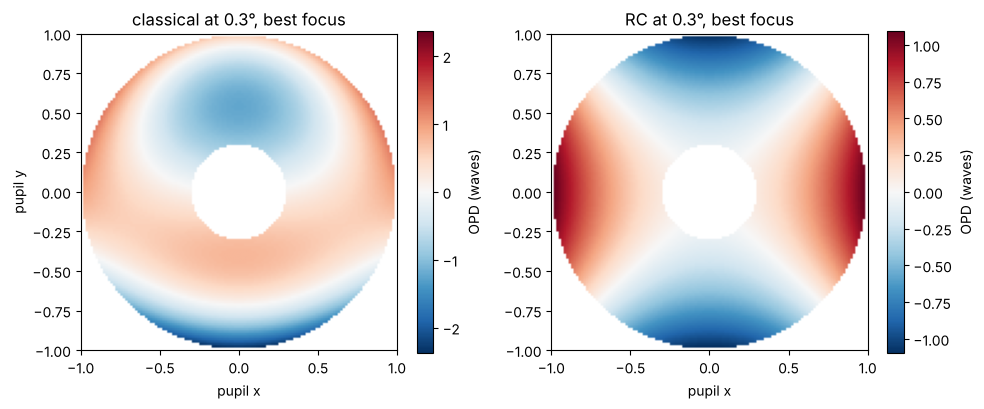

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
th = np.radians(0.3)
for ax, (name, S) in zip(axs, (("classical", cass), ("RC", rc))):
    dz = best[name, th][0]
    m = S.with_image_distance(S.surfaces[-1].thickness + dz).opd(th, 128)
    W = m.W.copy()
    PX, PY = np.meshgrid(m.px, m.py)
    W[np.hypot(PX, PY) < eps] = np.nan
    ok = np.isfinite(W)                   # remove piston and tilt (the comet's offset)
    A = np.c_[np.ones(ok.sum()), PX[ok], PY[ok]]
    W[ok] -= A @ np.linalg.lstsq(A, W[ok], rcond=None)[0]
    im = ax.imshow(W, extent=(-1, 1, -1, 1), origin="lower", cmap="RdBu_r",
                   vmin=-np.nanmax(np.abs(W)), vmax=np.nanmax(np.abs(W)))
    plt.colorbar(im, ax=ax, label="OPD (waves)")
    ax.set_title("%s at 0.3°, best focus" % name)
    ax.set_xlabel("pupil x")
axs[0].set_ylabel("pupil y")
plt.tight_layout()
plt.show()

## 4. What is left: astigmatism and field curvature

Neither design is free of astigmatism and field curvature. The angular
astigmatism (the diameter of the blur at the medial focus, between the
sagittal and the tangential line foci) is

$$\mathrm{AAS}_\mathrm{classical} = -\frac{\theta^2}{2F}\,\frac{m^2+\beta}{m(1+\beta)}, \qquad
\mathrm{AAS}_\mathrm{RC} = -\frac{\theta^2}{2F}\,\frac{m(2m+1)+\beta}{2m(1+\beta)},$$

slightly larger for the RC (the price for removing coma). Pure astigmatism
at the medial focus maps the pupil onto a uniform disk of diameter
$\mathrm{AAS}\cdot f$, whose rms radius is $\mathrm{AAS}\cdot f/(2\sqrt{2})$.

The images lie on a curved surface. The Petzval curvature of the two
mirrors is $-(2/R_1 - 2/R_2)$, and astigmatism adds twice its own
curvature $\mathrm{AAS}/(y\theta^2)$ to give the medial surface, on which the
best images lie at the height $h = f\tan\theta$ a distance
$h^2/(2R_\mathrm{medial})$ from the paraxial focal plane. The table compares
the formulas with `System.third_order()` (from the Seidel sums), with the
best focus found by tracing, and the rms spot radius with the
astigmatic disk:

In [12]:
for name, S in (("classical", cass), ("RC", rc)):
    a = tl.two_mirror_aberrations(D, f1, f, b, np.radians(0.1), "rc" if name == "RC" else "classical")
    to = S.third_order()
    print("%s: Petzval radius %.1f (third_order %.1f), medial radius %.1f (third_order %.1f) mm"
          % (name, a.petzval_radius, to.petzval_radius, a.medial_radius, to.medial_radius))

# the RC is free of third order spherical aberration only: its fifth order residual moves the
# best focus on the axis by a few µm, which we subtract
z0_rc = tl.best_focus(rc, 0.0, search=0.05)[0]
print("RC best focus on the axis: %.1f µm from the paraxial focus" % (z0_rc*1e3))

print("\n%-9s %6s %14s %14s %14s %14s" % ("", "field", "focus traced", "h^2/(2R_m)", "rms traced",
                                            "AAS f/(2√2)"))
for name, S, z0 in (("classical", cass, 0.0), ("RC", rc, z0_rc)):
    kind = "rc" if name == "RC" else "classical"
    for th in fields[1:]:
        a = tl.two_mirror_aberrations(D, f1, f, b, th, kind)
        dz, r = tl.best_focus(S, th, search=2.0, iterations=4)
        h = f*np.tan(th)
        print("%-9s %5.1f° %11.1f µm %11.1f µm %11.2f µm %11.2f µm"
              % (name, np.degrees(th), (dz - z0)*1e3, h**2/(2*a.medial_radius)*1e3, r*1e3,
                 abs(a.AAS)*f/(2*np.sqrt(2))*1e3))

classical: Petzval radius -2769.2 (third_order -2769.2), medial radius -1024.9 (third_order -1024.9) mm
RC: Petzval radius -2769.2 (third_order -2769.2), medial radius -921.6 (third_order -921.6) mm
RC best focus on the axis: 5.3 µm from the paraxial focus

           field   focus traced     h^2/(2R_m)     rms traced    AAS f/(2√2)


classical   0.1°       -95.0 µm       -95.1 µm       11.16 µm        1.32 µm


classical   0.2°      -379.8 µm      -380.4 µm       22.80 µm        5.30 µm


classical   0.3°      -854.5 µm      -856.0 µm       35.35 µm       11.91 µm


RC          0.1°      -105.1 µm      -105.8 µm        1.56 µm        1.56 µm


RC          0.2°      -420.2 µm      -423.1 µm        6.19 µm        6.24 µm


RC          0.3°      -945.4 µm      -951.9 µm       13.93 µm       14.03 µm


The traced focus shifts agree with the medial surface to better than 1 %.
For the RC the rms spot is the astigmatic disk, to 1 %; for the
classical Cassegrain the coma dominates. A flat detector placed at the
paraxial focus loses a lot at the edge of the field: below, the rms spot
radius of the RC over the field on the flat focal plane, on the best
(curved) surface, and the third order astigmatic limit. Telescopes with
large flat detectors therefore add a field flattener (a lens or two near
the focus), which also corrects some of the astigmatism.

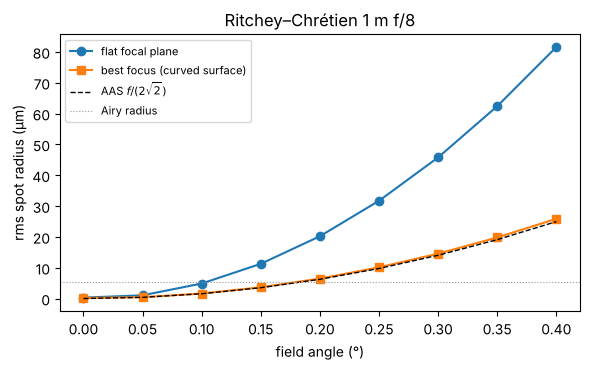

In [13]:
th_f = np.radians(np.linspace(0, 0.4, 9))
flat = [tl.spot(rc, t, eps).rms for t in th_f]
curved = [tl.best_focus(rc, t, eps, search=2.0)[1] for t in th_f]
aas = [abs(tl.two_mirror_aberrations(D, f1, f, b, t, "rc").AAS)*f/(2*np.sqrt(2)) for t in th_f]
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(np.degrees(th_f), np.array(flat)*1e3, "o-", label="flat focal plane")
ax.plot(np.degrees(th_f), np.array(curved)*1e3, "s-", label="best focus (curved surface)")
ax.plot(np.degrees(th_f), np.array(aas)*1e3, "k--", lw=1, label=r"AAS $f/(2\sqrt{2})$")
ax.axhline(airy*1e3, color="0.6", lw=0.8, ls=":", label="Airy radius")
ax.set_xlabel("field angle (°)")
ax.set_ylabel("rms spot radius (µm)")
ax.set_title("Ritchey–Chrétien 1 m f/8")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. The Schmidt camera

Bernhard Schmidt's idea (1930) goes the other way: keep a *spherical*
mirror, which has no preferred axis, and put the stop at its centre of
curvature. Every chief ray then passes through the centre and meets the
mirror along a normal; each field angle sees exactly the same mirror, so
there is no coma and no astigmatism at all, only spherical aberration
(the same for every field) and a focal surface that is a sphere of radius
$f$ concentric with the mirror. A thin aspheric plate in the stop removes
the spherical aberration. Its thickness profile ::

$$t(r) = \frac{r^4 - k\,r_m^2 r^2}{4(n-1)R^3}$$

cancels the third order term; the $r^2$ term (a weak lens) puts the
neutral zone, where the plate is thickest, at $r_m\sqrt{k/2}$. With
$k = 3/2$ (neutral zone at 0.866 of the aperture) the chromatic error is
smallest. `schmidt_camera()` starts from this formula and then fits the
higher order terms ($r^6$, $r^8$) to the traced on-axis wavefront, which a
fast mirror needs. A 300 mm f/2 camera with an N-BK7 plate:

efl 603.5 mm, plate index 1.51853
on-axis rms wavefront: thin plate formula 0.158 waves, with r^6 and r^8 fitted 0.00011 waves
plate coefficients A4, A6, A8: (np.float64(-2.725555108432505e-10), np.float64(-2.8005231816203955e-16), np.float64(-3.9087746280960284e-22))


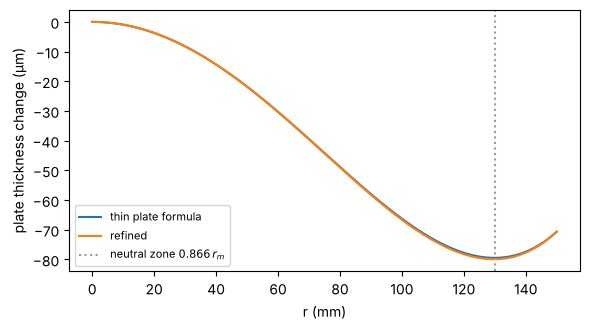

In [14]:
D_s, F_s = 300.0, 2.0
thin = tl.schmidt_camera(D_s, F_s, refine=0, wavelength=lam)
sch = tl.schmidt_camera(D_s, F_s, wavelength=lam)
f_s = sch.paraxial().efl
print("efl %.1f mm, plate index %.5f" % (f_s, sch.n[1]))
print("on-axis rms wavefront: thin plate formula %.3f waves, with r^6 and r^8 fitted %.5f waves"
      % (thin.rms_opd(0.0), sch.rms_opd(0.0)))
print("plate coefficients A4, A6, A8:", sch.surfaces[0].aspheric)

r = np.linspace(0, D_s/2, 200)
fig, ax = plt.subplots(figsize=(6, 3.4))
for S, lab in ((thin, "thin plate formula"), (sch, "refined")):
    s0 = S.surfaces[0]
    t = -s0.sag(r**2)                      # thickness change, flat back
    ax.plot(r, (t - t[0])*1e3, label=lab)
ax.axvline(D_s/2*np.sqrt(1.5/2), color="0.6", ls=":", label="neutral zone $0.866\\,r_m$")
ax.set_xlabel("r (mm)")
ax.set_ylabel("plate thickness change (µm)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The plate profile varies by less than a tenth of a millimetre, a
figuring job rather than a lens. Off the axis the images stay sharp, but
on a curved surface: on the flat paraxial focal plane the blur grows with
the defocus $f(1-\cos\theta)$, on the sphere of radius $f$ it stays
within about the Airy disk. The small comatic residual comes from the
plate, which the oblique beams see foreshortened and through a slightly
longer path, and it grows with the field angle. The traced best focus against $-f(1-\cos\theta)$:

 field     focus traced      -f(1 - cos)       rms flat     rms curved


    0°        0.0000 mm       -0.0000 mm        0.00 µm        0.00 µm


    1°       -0.0923 mm       -0.0919 mm       16.57 µm        0.42 µm


    2°       -0.3691 mm       -0.3676 mm       66.30 µm        0.92 µm


    3°       -0.8305 mm       -0.8271 mm      149.26 µm        1.57 µm


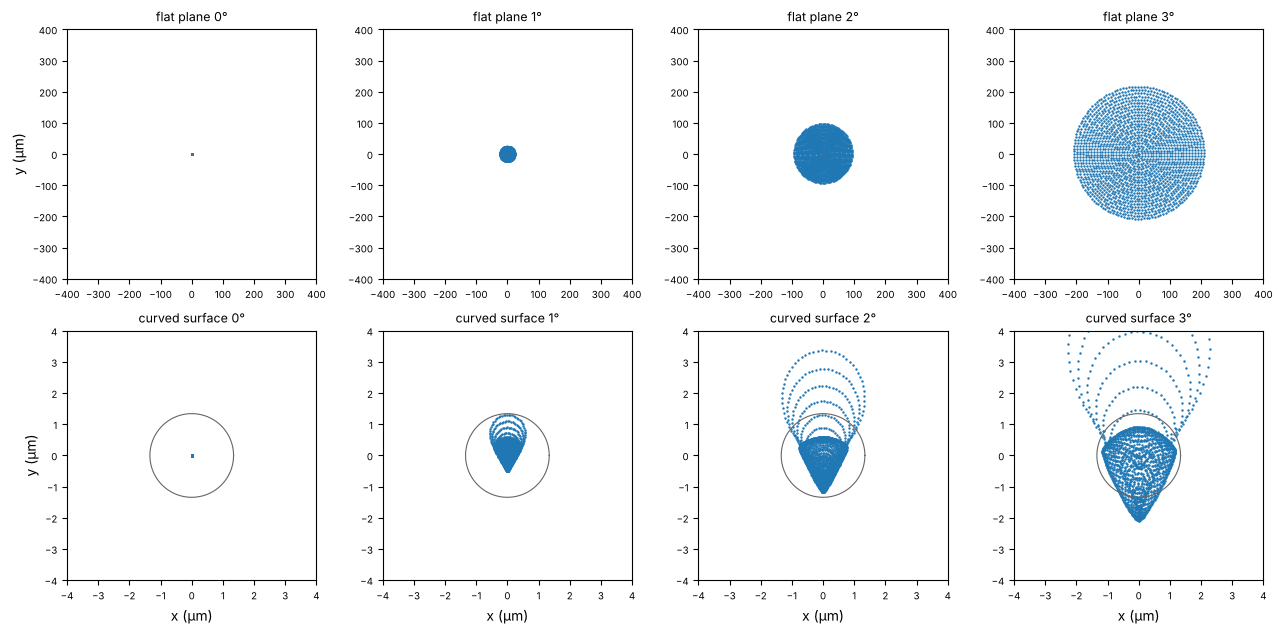

In [15]:
fields_s = np.radians([0.0, 1.0, 2.0, 3.0])
airy_s = 1.22*lam*F_s
fig, axs = plt.subplots(2, 4, figsize=(13, 6.4))
print("%6s %16s %16s %14s %14s" % ("field", "focus traced", "-f(1 - cos)", "rms flat", "rms curved"))
for k, th in enumerate(fields_s):
    dz, r_b = tl.best_focus(sch, th, search=1.5, iterations=4)
    s_flat = tl.spot(sch, th, n_rings=24)
    s_best = tl.spot(sch.with_image_distance(sch.surfaces[-1].thickness + dz), th, n_rings=24)
    show_spot(axs[0, k], s_flat, 400, airy_s, title="flat plane %.0f°" % np.degrees(th))
    show_spot(axs[1, k], s_best, 4, airy_s, title="curved surface %.0f°" % np.degrees(th))
    print("%5.0f° %13.4f mm %13.4f mm %11.2f µm %11.2f µm"
          % (np.degrees(th), dz, -f_s*(1 - np.cos(th)), s_flat.rms*1e3, s_best.rms*1e3))
for ax in axs[1]:
    ax.set_xlabel("x (µm)")
axs[0, 0].set_ylabel("y (µm)")
axs[1, 0].set_ylabel("y (µm)")
plt.tight_layout()
plt.show()

Note the different scales: 400 µm on the flat plane, 4 µm on the curved
surface. Schmidt cameras were therefore used with photographic plates bent
to the focal sphere (and today with field flatteners or curved
detectors). A 6° field at f/2 with images of a few micrometres is far out
of reach of any of the two-mirror telescopes above, which is why the big
sky surveys of the 20th century (the Palomar and UK Schmidt telescopes)
used them.

### Chromatism of the plate

The plate is made for one wavelength. At another, its index differs by
$\delta n$ and its effect scales by $1 + \delta n/(n-1)$: a residual
spherical aberration of $\delta n/(n-1)$ times the mirror's. With the
neutral zone at $0.866\,r_m$ the residual is a Chebyshev polynomial whose
ray errors stay within their value at the rim, and the blur has the
angular diameter

$$\beta = \frac{\delta n}{128\,(n-1)\,F^3}.$$

The traced spot diameters at the design focus for the F and C lines and
for 400 nm against the formula, and the blur over the visible range:

  lambda         dn  traced diameter          formula
 486.1 nm    0.00391          1.526"          1.517"
 656.3 nm   -0.00415          1.623"          1.612"
 400.0 nm    0.01242          4.853"          4.824"


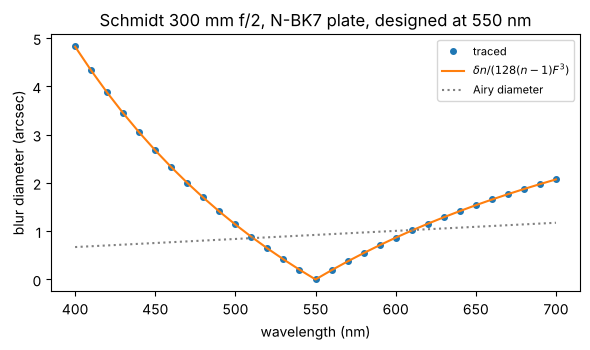

In [16]:
n0 = sch.n[1]
print("%8s %10s %16s %16s" % ("lambda", "dn", "traced diameter", "formula"))
for wl in (486.1e-6, 656.3e-6, 400e-6):
    S = sch.with_wavelength(wl)
    s = tl.spot(S, 0.0, n_rings=32)
    diam = 2*np.max(np.hypot(s.x - s.centroid[0], s.y - s.centroid[1]))/f_s
    pred = tl.schmidt_chromatic_blur(F_s, n0, S.n[1] - n0)
    print("%6.1f nm %10.5f %14.3f\" %14.3f\"" % (wl*1e6, S.n[1] - n0, diam/arcsec, pred/arcsec))

wls = np.linspace(400e-6, 700e-6, 31)
diam, pred = [], []
for wl in wls:
    S = sch.with_wavelength(wl)
    s = tl.spot(S, 0.0, n_rings=16)
    diam.append(2*np.max(np.hypot(s.x - s.centroid[0], s.y - s.centroid[1]))/f_s/arcsec)
    pred.append(tl.schmidt_chromatic_blur(F_s, n0, S.n[1] - n0)/arcsec)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(wls*1e6, diam, "o", ms=4, label="traced")
ax.plot(wls*1e6, pred, "-", label=r"$\delta n/(128(n-1)F^3)$")
ax.plot(wls*1e6, 2*1.22*wls/D_s/arcsec, ":", color="0.5", label="Airy diameter")
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("blur diameter (arcsec)")
ax.set_title("Schmidt 300 mm f/2, N-BK7 plate, designed at 550 nm")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The chromatic blur goes with $1/F^3$: at f/2 it is 1.5 arcseconds at the F
and C lines and 5 at 400 nm, comparable with the seeing and far larger
than the Airy disk;
at f/1 it would be eight times worse. Achromatic plates of two glasses, or
the Baker–Schmidt and Schmidt–Cassegrain variants, reduce it.

## Summary

| design | on axis | coma | astigmatism | image surface |
|---|---|---|---|---|
| paraboloid (Newtonian) | perfect | $3\theta/(16F^2)$ | $\theta^2/(2F)$ | medial radius $f$ |
| classical Cassegrain | perfect | as a paraboloid of the system $F$ | $\frac{\theta^2}{2F}\frac{m^2+\beta}{m(1+\beta)}$ | Petzval + astigmatism |
| Ritchey–Chrétien | fifth order spherical only | none | $\frac{\theta^2}{2F}\frac{m(2m+1)+\beta}{2m(1+\beta)}$ | Petzval + astigmatism |
| Schmidt camera | plate residual, chromatic $\delta n/(128(n-1)F^3)$ | none | none | sphere of radius $f$ |

All traced numbers agreed with the third order formulas to a few per
mille (coma, Seidel sums) or about 1 % (best focus, rms spots); what
remains are higher order terms such as the fifth order spherical
aberration of the RC.

## References

- K. Schwarzschild, "Untersuchungen zur geometrischen Optik II",
  Astronomische Mitteilungen der Königlichen Sternwarte zu Göttingen 10
  (1905).
- G. W. Ritchey and H. Chrétien, "Sur un nouveau type de télescope
  photographique", C. R. Acad. Sci. Paris 185, 266 (1927).
- B. Schmidt, "Ein lichtstarkes komafreies Spiegelsystem", Mitteilungen
  der Hamburger Sternwarte in Bergedorf 7, 15–17 (1932).
- D. J. Schroeder, *Astronomical Optics*, 2nd ed., Academic Press (2000),
  chapters 4–6 and 8.
- R. N. Wilson, *Reflecting Telescope Optics I*, 2nd ed., Springer (2007).
- W. T. Welford, *Aberrations of Optical Systems*, Adam Hilger (1986).

In [17]:
print("notebook run time %.0f s" % (time.time() - t_start))

notebook run time 14 s
